https://arxiv.org/abs/1502.03167

In [1]:
from helpers import *

Activation: Ideal initial loss

In [2]:
logits = torch.zeros(27)
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()

loss, -probs[2].log(), -torch.tensor(1/27).log()

(tensor(3.2958), tensor(3.2958), tensor(3.2958))

In [3]:
logits = torch.randn(27) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs.log().mean()
loss, -probs[2].log()

(tensor(22.4880), tensor(10.3337))

training

In [5]:
nvec = 2

EMB = torch.randn(27, nvec)

nin = nvec * context_size 
W1 = torch.randn((nin,300))
b1 = torch.randn(300)

W2 = torch.randn((300,27)) * 0.01 # minimize std so logits are initially the same
b2 = torch.randn(27) * 0.1

params = [EMB, W1, b1, W2, b2]

for p in params:
	p.requires_grad = True


lossi = []

for i in range(100000):
	batchsize = 32

	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))

	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx]

	h = emb.view(-1, nin) @ W1 + b1
	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)

	for p in params:
		p.grad = None

	loss.backward()

	lr = 0.1 if i < 100000 else 0.01
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad

	lossi.append(loss.item())
	# break
print(loss.item())

2.6946117877960205


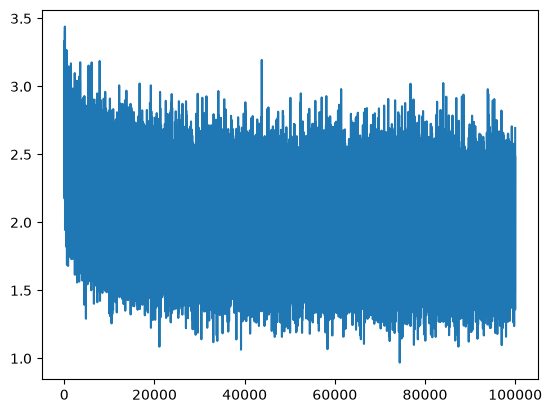

In [6]:
plt.plot(lossi)

unnormalized

(array([3091.,  230.,  203.,   92.,  108.,   97.,   68.,   82.,   50.,
          50.,   41.,   30.,   44.,   28.,   30.,   39.,   31.,   56.,
          16.,   33.,   34.,   65.,   68.,   68.,   93.,  158.,   38.,
          50.,   18.,   52.,   37.,   38.,   36.,   75.,   18.,   41.,
          31.,   78.,   24.,   43.,   46.,   79.,   76.,   62.,   85.,
         126.,  132.,  155.,  195., 3160.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

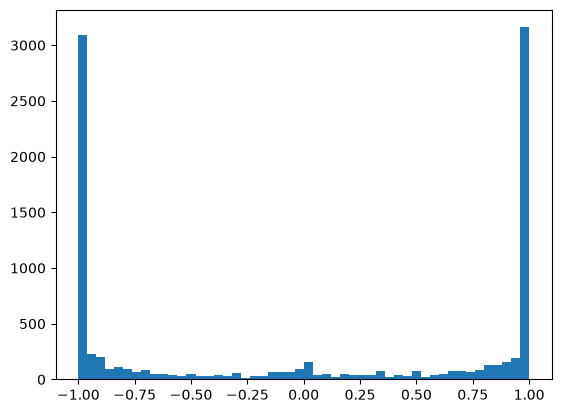

In [8]:
plt.hist(layer.view(-1).tolist(), 50)

tanh(h) = -/+ 1 ------> dtanh/dh = 1 - tanh(h)^2 = 0. AKA vanishing gradients

(array([  1.,   2.,   1.,   0.,   0.,   2.,   4.,   6.,  12.,  28.,  18.,
         48.,  61.,  75., 118., 171., 266., 279., 282., 310., 326., 374.,
        479., 462., 660., 695., 852., 663., 490., 523., 344., 365., 282.,
        288., 241., 221., 197., 138.,  91.,  61.,  33.,  40.,  46.,  12.,
         19.,   4.,   3.,   4.,   1.,   2.]),
 array([-2.02948494e+01, -1.95150427e+01, -1.87352361e+01, -1.79554294e+01,
        -1.71756227e+01, -1.63958160e+01, -1.56160094e+01, -1.48362027e+01,
        -1.40563960e+01, -1.32765894e+01, -1.24967827e+01, -1.17169760e+01,
        -1.09371693e+01, -1.01573627e+01, -9.37755600e+00, -8.59774933e+00,
        -7.81794266e+00, -7.03813599e+00, -6.25832932e+00, -5.47852264e+00,
        -4.69871597e+00, -3.91890930e+00, -3.13910263e+00, -2.35929596e+00,
        -1.57948929e+00, -7.99682617e-01, -1.98759460e-02,  7.59930725e-01,
         1.53973740e+00,  2.31954407e+00,  3.09935074e+00,  3.87915741e+00,
         4.65896408e+00,  5.43877075e+00,  6.21857

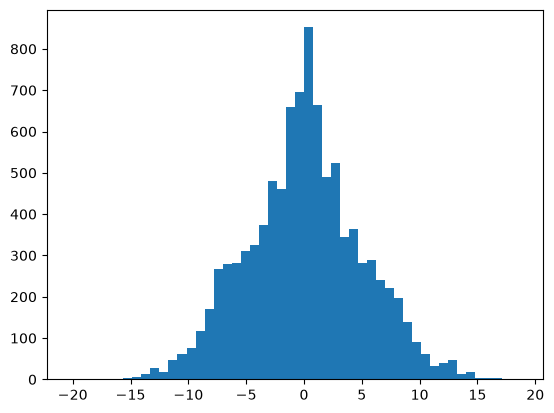

In [9]:
plt.hist(h.view(-1).tolist(), 50)

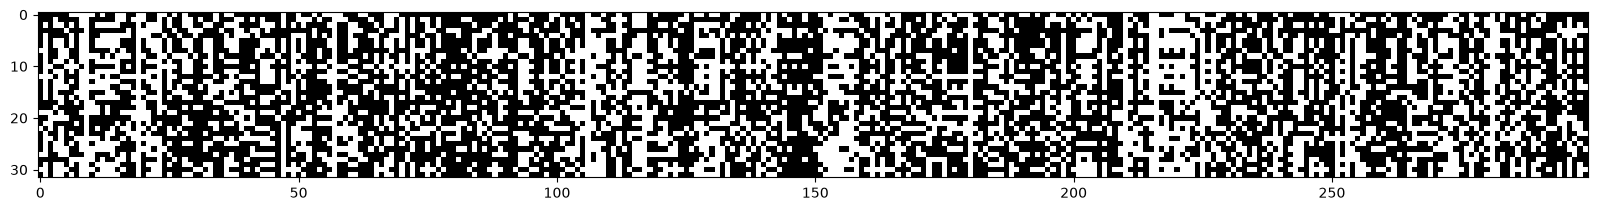

In [10]:
# black is dead neuron, brain damage
plt.figure(figsize=(20, 10))
plt.imshow(layer.abs() < 0.99, cmap="gray", interpolation="nearest")

normalized initialization (Kaiming init)

- https://arxiv.org/pdf/1502.01852
- https://docs.pytorch.org/docs/2.14/nn.init.html#torch.nn.init.kaiming_normal_

BatchNorm
(normalize every minibatch), backprop is now coupled across batch -- increases jitter inside
- https://arxiv.org/pdf/1502.03167

In [12]:
nvec = 10
EMB = torch.randn(27, nvec)
nin = nvec * context_size 
W1 = torch.randn((nin,200)) * (5/3) / nin**0.5 # Kaiming Init
b1 = torch.randn(200) * 0.01
W2 = torch.randn((200,27)) * 0.01
b2 = torch.randn(27) * 0.1

# batch norm adjust
gamma, beta = torch.ones((1,200)), torch.zeros((1,200))

params = [EMB, W1, b1, W2, b2, gamma, beta]

for p in params:
	p.requires_grad = True
lossi = []
for i in range(100000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx]
	h = emb.view(-1, nin) @ W1 + b1

	# BATCHNORM
	h = (h - h.mean(0,keepdim=True)) / h.std(0,keepdim=True)
	h = gamma * h + beta

	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)
	for p in params:
		p.grad = None
	loss.backward()
	lr = 0.1 if i < 100000 else 0.01
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad
	lossi.append(loss.item())
print(loss.item())

2.043034553527832


batchnorm running

In [13]:
nvec = 10
EMB = torch.randn(27, nvec)
nin = nvec * context_size 
nhidden = 200
W1 = torch.randn((nin,nhidden)) * (5/3) / nin**0.5
# REDUNDANT
# b1 = torch.randn(nhidden) * 0.01
W2 = torch.randn((nhidden,27)) * 0.01
b2 = torch.randn(27) * 0.1


# batch norm adjust
gamma, beta = torch.ones((1,nhidden)), torch.zeros((1,nhidden))

params = [EMB, W1, W2, b2, gamma, beta]

for p in params:
	p.requires_grad = True

lossi = []

# not in params
bnsrunning, bnmrunning = torch.ones((1,nhidden)), torch.zeros((1,nhidden))

for i in range(100000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx]
	h = emb.view(-1, nin) @ W1

	# BATCHNORM running
	bnmi, bnsi = h.mean(0,keepdim=True), h.std(0,keepdim=True)
	
	# collect the bns
	with torch.no_grad():
		bnmrunning = 0.99 * bnmrunning + 0.01 * bnmi
		bnsrunning = 0.99 * bnsrunning + 0.01 * bnsi

	h = (h - bnmi) / bnsi
	h = gamma * h + beta


	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)
	for p in params:
		p.grad = None
	loss.backward()
	lr = 0.1 if i < 100000 else 0.01
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad
	lossi.append(loss.item())
	# break

print(loss.item())

1.3886024951934814


LOSS with batchnorm

In [18]:
@torch.no_grad()
def get_loss(split):
	X, Y = {
		"train": (Xtrain, Ytrain),
		"val": (Xval, Yval)
	}[split]

	emb = EMB[X]
	h = emb.view(-1, nin) @ W1 + b1

	# BATCHNORM
	h = (h - bnmrunning) / bnsrunning
	h = gamma * h + beta

	layer = torch.tanh(h)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, Y)

	print(split, loss.item())

get_loss("train")
get_loss("val")


train 1.7498670816421509
val 2.615377902984619


In [17]:
# gen names
alpha = "abcdefghijklmnopqrstuvwxyz."

for i in range(20):
	ctx = [0] * context_size 
	name = ""
	k = 0

	while k < 20:
		emb = EMB[ctx]

		layer = torch.tanh(emb.view(-1, nin) @ W1)
		logits = layer @ W2 + b2

		probs = torch.softmax(logits, axis=1)

		cidx = torch.multinomial(probs, num_samples=1, replacement=True).item()
		c = alpha[cidx]
		name += c

		if c == ".":
			break

		ctx = ctx[1:] + [cidx]
		k += 1

	print(name)

haniah.
mckennatatrieva.
zhusgaxselennalivhya
vhnavya.
mzizlishaqbexledna.
brosjqoif.
jamsuyth.
difr.
hanathponmfhith.
huvr.
zzela.
beth.
whazavelyszippeigh.
vevya.
mofzilveth.
jeh.
vevsezzipporiscazque
hagavranzela.
zabebj.
gettieltipur.


entropy of initial letter.

<BarContainer object of 27 artists>

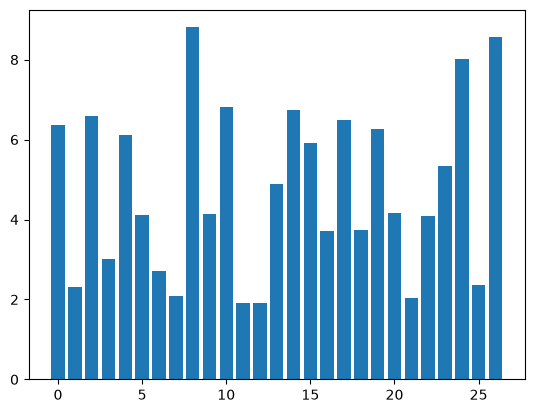

In [19]:
emb = EMB[[0,0,0]]
layer = torch.tanh(emb.view(-1, nin) @ W1)
logits = layer @ W2 + b2
probs = -torch.softmax(logits, axis=1).log()
plt.bar(range(probs.shape[1]), probs[0].detach().numpy())